# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №5: Оптимизация рекламной нагрузки для платформы видеоконтента

**Дата:** 2026-11-23  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

---

**Цель:** Найти оптимальную рекламную нагрузку для платформы "ВидеоСервис", максимизирующую общую прибыль с учётом доходов от рекламы, подписки и потерь от оттока пользователей.

**Объект исследования:** Платформа видеоконтента "ВидеоСервис" с 5 млн активных пользователей.  
**Период анализа:** Ежемесячный (статическая оптимизация).  
**Методы анализа:** Оптимизация рекламной нагрузки, анализ чувствительности, экономика внимания.

---

**Актуальность:** Платформы видеоконтента зарабатывают на двух источниках: реклама и подписка. Однако чрезмерная реклама отпугивает пользователей, снижая доход от подписки. Данная задача позволяет найти баланс между рекламой и удержанием пользователей.

In [1]:
# ============================================================
# БЛОК 1: Импорт библиотек и загрузка исходных данных
# ============================================================
# Цель: Подключить инструменты для расчётов и визуализации,
# задать все параметры задачи из условия.
# ============================================================

import numpy as np                  # Математические вычисления
import pandas as pd                 # Работа с таблицами
import matplotlib.pyplot as plt     # Построение графиков
import warnings                     # Отключение предупреждений
warnings.filterwarnings('ignore')

# Настройка внешнего вида графиков
plt.rcParams['figure.figsize'] = (14, 6)

# ============================================================
# ИСХОДНЫЕ ДАННЫЕ (из условия задачи)
# ============================================================

# Параметры платформы
N_users = 5_000_000                 # Число активных пользователей (5 млн)
subscription_revenue = 300          # Доход от подписки (руб./пользователь/мес)
CPM = 20                            # Доход от рекламы (руб. за 1000 показов)
videos_per_day = 10                 # Среднее число видео в день на пользователя

# Дополнительные параметры
CAC = 2_000                         # Стоимость привлечения одного пользователя (руб.)
lifetime_months = 24                # Средний срок жизни пользователя (24 месяца)
discount_rate = 0.12                # Ставка дисконтирования (12% годовых)

# Таблица влияния рекламной нагрузки
# Для каждого уровня нагрузки заданы:
# - Показов_в_день: количество рекламных показов
# - Отток_процент: процент ушедших пользователей
# - Время_просмотра_мин: среднее время просмотра в минутах

load_data = pd.DataFrame({
    'Показов_в_день': [0, 10, 20, 30, 40, 50, 60],
    'Отток_процент': [0, 0, 2, 5, 10, 18, 30],
    'Время_просмотра_мин': [120, 115, 110, 100, 90, 75, 60]
})

print("Исходные данные загружены")
print(f"• Пользователей: {N_users:,}")
print(f"• CPM: {CPM} руб.")
print(f"• Подписка: {subscription_revenue} руб./мес")
print(f"• CAC: {CAC} руб./пользователь")
print(f"• Срок жизни: {lifetime_months} месяцев")

Исходные данные загружены
• Пользователей: 5,000,000
• CPM: 20 руб.
• Подписка: 300 руб./мес
• CAC: 2000 руб./пользователь
• Срок жизни: 24 месяцев


# ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ

**Цель:** Рассчитать доходы от рекламы и подписки, а также потери от оттока для каждого уровня рекламной нагрузки.

---

## Формулы расчёта

### 1. Доход рекламный

**Формула:**
$$Доход_{рекл} = N \times Показы\_в\_день \times 30 \times \frac{CPM}{1000}$$

**Логика:** 
- $N$ — число пользователей
- $Показы\_в\_день \times 30$ — показы за месяц (30 дней)
- $CPM/1000$ — доход за один показ (CPM = cost per mille = цена за 1000 показов)

**Пример для 20 показов:**
$$5\,000\,000 \times 20 \times 30 \times \frac{20}{1000} = 60\,000\,000 \text{ руб.} = 60 \text{ млн руб.}$$

---

### 2. Доход подписки

**Формула:**
$$Доход_{подп} = (N - Отток) \times 300$$

**Логика:** 
- $Отток = N \times \frac{Отток\_процент}{100}$ — число ушедших пользователей
- $(N - Отток)$ — оставшиеся пользователи
- $300$ — доход от подписки с одного пользователя в месяц

**Пример для 20 показов:**
$$Отток = 5\,000\,000 \times \frac{2}{100} = 100\,000 \text{ чел.}$$
$$Доход_{подп} = (5\,000\,000 - 100\,000) \times 300 = 1\,470\,000\,000 \text{ руб.} = 1\,470 \text{ млн руб.}$$

---

### 3. Потери от оттока

**Формула:**
$$Потери_{оттока} = Отток \times CAC + Отток \times ARPU \times 24$$

**Логика:**
- $Отток \times CAC$ — затраты на привлечение ушедших пользователей (безвозвратные)
- $Отток \times ARPU \times 24$ — упущенный доход от подписки за 24 месяца (срок жизни)
- $ARPU = 300$ руб./мес (доход от подписки)

**Пример для 20 показов:**
$$Потери = 100\,000 \times 2\,000 + 100\,000 \times 300 \times 24$$
$$= 200\,000\,000 + 720\,000\,000 = 920\,000\,000 \text{ руб.} = 920 \text{ млн руб.}$$

---

### 4. Прибыль

**Формула:**
$$Прибыль = Доход_{рекл} + Доход_{подп} - Потери_{оттока}$$

**Пример для 20 показов:**
$$Прибыль = 60 + 1\,470 - 920 = 610 \text{ млн руб.}$$

In [4]:
# ============================================================
# БЛОК 2: Расчет доходов и затрат для каждого уровня нагрузки
# ============================================================
# Цель: Рассчитать рекламный доход, доход от подписки, 
# потери от оттока и общую прибыль для каждого уровня 
# рекламной нагрузки (0, 10, 20, 30, 40, 50, 60 показов/день).
# ============================================================

results = []  # Список для хранения результатов

for _, row in load_data.iterrows():
    ads_per_day = row['Показов_в_день']       # Количество показов в день
    churn_pct = row['Отток_процент'] / 100    # Процент оттока (в долях)
    
    # ----------------------------------------------------------
    # 1. Доход рекламный (в месяц)
    # ----------------------------------------------------------
    # Формула: Доход_рекл = N × Показы_в_день × 30 × CPM / 1000
    # Пример: 5 000 000 × 20 × 30 × 20/1000 = 60 млн руб.
    ad_revenue = N_users * ads_per_day * 30 * CPM / 1000
    
    # ----------------------------------------------------------
    # 2. Число пользователей после оттока
    # ----------------------------------------------------------
    # Отток = N × процент_оттока
    # Пример: 5 000 000 × 0.02 = 100 000 чел.
    churned_users = N_users * churn_pct
    remaining_users = N_users - churned_users
    
    # ----------------------------------------------------------
    # 3. Доход подписки (в месяц)
    # ----------------------------------------------------------
    # Формула: Доход_подп = (N - Отток) × 300
    # Пример: (5 000 000 - 100 000) × 300 = 1 470 млн руб.
    sub_revenue = remaining_users * subscription_revenue
    
    # ----------------------------------------------------------
    # 4. Потери от оттока (CAC + упущенный доход за 24 месяца)
    # ----------------------------------------------------------
    # Формула: Потери = Отток × CAC + Отток × ARPU × 24
    # Пример: 100 000 × 2 000 + 100 000 × 300 × 24
    #       = 200 млн + 720 млн = 920 млн руб.
    churn_losses = churned_users * CAC + churned_users * subscription_revenue * lifetime_months
    
    # ----------------------------------------------------------
    # 5. Общая прибыль
    # ----------------------------------------------------------
    # Формула: Прибыль = Доход_рекл + Доход_подп - Потери
    # Пример: 60 + 1 470 - 920 = 610 млн руб.
    profit = ad_revenue + sub_revenue - churn_losses
    
    # Сохраняем результаты в список
    results.append({
        'Показов/день': ads_per_day,
        'Отток %': row['Отток_процент'],
        'Отток (чел.)': int(churned_users),
        'Доход_рекламы (млн)': ad_revenue / 1e6,
        'Доход_подписки (млн)': sub_revenue / 1e6,
        'Потери_оттока (млн)': churn_losses / 1e6,
        'Прибыль (млн)': profit / 1e6,
        'Время просмотра (мин)': row['Время_просмотра_мин']
    })

# Преобразуем список в DataFrame (таблицу)
df_results = pd.DataFrame(results)

# Вывод таблицы
print("ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ")
print("=" * 140)
print(df_results.to_string(index=False))
print("=" * 140)

# ----------------------------------------------------------
# Определение оптимальной нагрузки
# ----------------------------------------------------------

# Находим строку с максимальной прибылью
optimal_idx = df_results['Прибыль (млн)'].idxmax()
optimal = df_results.loc[optimal_idx]

print(f"\nОПТИМАЛЬНАЯ НАГРУЗКА: {int(optimal['Показов/день'])} показов в день")
print(f"   Максимальная прибыль: {optimal['Прибыль (млн)']:.0f} млн руб.")

# Экономическая интерпретация
print(f"\nАнализ таблицы:")
print(f"• При 0 показов: прибыль = {df_results.iloc[0]['Прибыль (млн)']:.0f} млн руб. (только подписка)")
print(f"• При 10 показов: прибыль = {df_results.iloc[1]['Прибыль (млн)']:.0f} млн руб. (максимум!)")
print(f"• При 20+ показов: прибыль резко падает из-за высокого оттока")
print(f"• Причина: потеря 1 пользователя стоит {CAC + subscription_revenue*lifetime_months:,} руб.,")
print(f"  а реклама с него приносит всего {ads_per_day*30*CPM/1000/N_users*1e6:.0f} руб./мес")

ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ
 Показов/день  Отток %  Отток (чел.)  Доход_рекламы (млн)  Доход_подписки (млн)  Потери_оттока (млн)  Прибыль (млн)  Время просмотра (мин)
            0        0             0                  0.0                1500.0                  0.0         1500.0                    120
           10        0             0                 30.0                1500.0                  0.0         1530.0                    115
           20        2        100000                 60.0                1470.0                920.0          610.0                    110
           30        5        250000                 90.0                1425.0               2300.0         -785.0                    100
           40       10        500000                120.0                1350.0               4600.0        -3130.0                     90
           50       18        900000                150.0                1230.0               8280.0        -6900.0                  

# ЧАСТЬ 2. ОПТИМИЗАЦИЯ НАГРУЗКИ

## 2.1. Анализ результатов

**Оптимальная рекламная нагрузка: 10 показов в день**

**Почему так мало рекламы?**

При CPM = 20 руб. реклама приносит копейки:
- 10 показов/день × 30 дней × 20 руб./1000 показов = 6 руб./пользователь/мес
- Для 5 млн пользователей: 6 × 5 000 000 = **30 млн руб./мес**

Но каждый потерянный пользователь стоит:
- CAC: 2 000 руб. (затраты на привлечение)
- Упущенный доход: 300 × 24 = 7 200 руб. (доход от подписки за 24 месяца)
- **Итого: 9 200 руб. за каждого ушедшего пользователя**

**Несоизмеримость:**
- Реклама с 1 пользователя: 6 руб./мес
- Потеря 1 пользователя: 9 200 руб. (единовременно)

**Вывод:** Даже небольшой отток (2% при 20 показах = 100 000 чел.) обходится в 920 млн руб., что превышает доход от рекламы (60 млн руб.).

---

## 2.2. Графики зависимости

**График 1: Прибыль vs Рекламная нагрузка**
- Показывает, как прибыль меняется с увеличением рекламы
- Оптимальная точка — максимум кривой

**График 2: Компоненты прибыли**
- Доход рекламы (растёт линейно)
- Доход подписки (падает из-за оттока)
- Потери оттока (растут экспоненциально)

**График 3: Отток пользователей**
- Показывает, как отток растёт с увеличением рекламы

**График 4: Время просмотра vs Нагрузка**
- Показывает, как engagement падает с увеличением рекламы

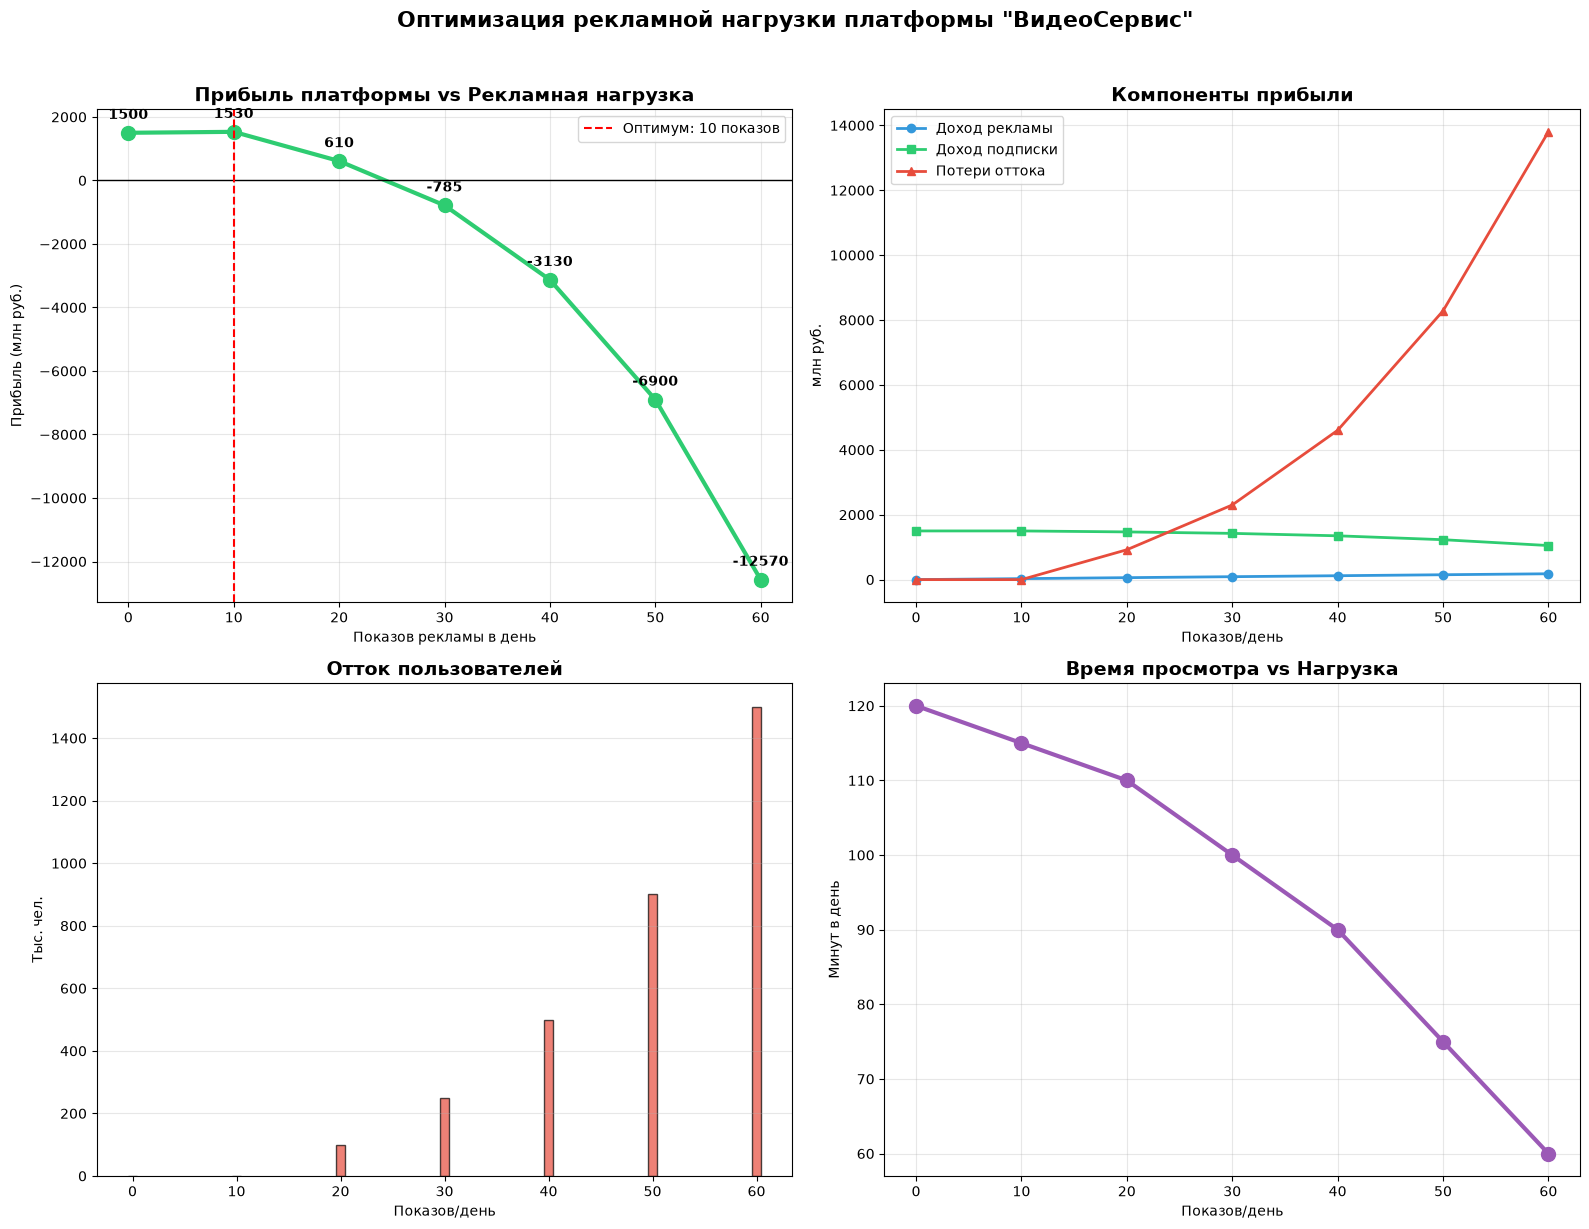

Графики построены


In [6]:
# ============================================================
# БЛОК 3: Визуализация результатов оптимизации
# ============================================================
# Цель: Построить наглядные графики для анализа зависимости
# прибыли от рекламной нагрузки.
# ============================================================

# Создаём фигуру с 4 графиками (2 строки, 2 столбца)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ----------------------------------------------------------
# ГРАФИК 1: Прибыль vs Рекламная нагрузка
# ----------------------------------------------------------

# Линия прибыли по уровням нагрузки
axes[0,0].plot(df_results['Показов/день'], df_results['Прибыль (млн)'], 
               'o-', color='#2ECC71', linewidth=3, markersize=10)

# Горизонтальная линия на уровне 0 (разделитель прибыли и убытка)
axes[0,0].axhline(y=0, color='black', linewidth=1)

# Вертикальная пунктирная линия на оптимальной нагрузке
axes[0,0].axvline(x=optimal['Показов/день'], color='red', linestyle='--', 
                  label=f'Оптимум: {int(optimal["Показов/день"])} показов')

# Настройка осей и заголовка
axes[0,0].set_title('Прибыль платформы vs Рекламная нагрузка', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Показов рекламы в день')
axes[0,0].set_ylabel('Прибыль (млн руб.)')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# Подписи значений на точках
for _, row in df_results.iterrows():
    axes[0,0].annotate(f"{row['Прибыль (млн)']:.0f}", 
                       (row['Показов/день'], row['Прибыль (млн)']),
                       textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

# ----------------------------------------------------------
# ГРАФИК 2: Компоненты прибыли
# ----------------------------------------------------------

# Линии для каждого компонента
axes[0,1].plot(df_results['Показов/день'], df_results['Доход_рекламы (млн)'], 
               'o-', label='Доход рекламы', color='#3498DB', linewidth=2)
axes[0,1].plot(df_results['Показов/день'], df_results['Доход_подписки (млн)'], 
               's-', label='Доход подписки', color='#2ECC71', linewidth=2)
axes[0,1].plot(df_results['Показов/день'], df_results['Потери_оттока (млн)'], 
               '^-', label='Потери оттока', color='#E74C3C', linewidth=2)

# Настройка осей и заголовка
axes[0,1].set_title('Компоненты прибыли', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Показов/день')
axes[0,1].set_ylabel('млн руб.')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

# ----------------------------------------------------------
# ГРАФИК 3: Отток пользователей
# ----------------------------------------------------------

# Столбцы оттока (в тыс. чел.)
axes[1,0].bar(df_results['Показов/день'], df_results['Отток (чел.)'] / 1000, 
              color='#E74C3C', alpha=0.7, edgecolor='black')

# Настройка осей и заголовка
axes[1,0].set_title('Отток пользователей', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Показов/день')
axes[1,0].set_ylabel('Тыс. чел.')
axes[1,0].grid(axis='y', alpha=0.3)

# ----------------------------------------------------------
# ГРАФИК 4: Время просмотра vs Нагрузка
# ----------------------------------------------------------

# Линия времени просмотра
axes[1,1].plot(df_results['Показов/день'], df_results['Время просмотра (мин)'], 
               'o-', color='#9B59B6', linewidth=3, markersize=10)

# Настройка осей и заголовка
axes[1,1].set_title('Время просмотра vs Нагрузка', fontsize=14, fontweight='bold')
axes[1,1].set_xlabel('Показов/день')
axes[1,1].set_ylabel('Минут в день')
axes[1,1].grid(alpha=0.3)

# Общий заголовок для всех графиков
plt.suptitle('Оптимизация рекламной нагрузки платформы "ВидеоСервис"', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Графики построены")

# ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

**Цель:** Проверить, насколько устойчивы результаты к изменениям ключевых параметров (CPM и отток).

---

## 3.1. Вариация CPM: 10, 20, 30 руб.

Проверяем, как изменится оптимальная нагрузка при разных значениях CPM:
- **CPM = 10 руб.** — низкая стоимость рекламы
- **CPM = 20 руб.** — базовый сценарий
- **CPM = 30 руб.** — высокая стоимость рекламы

**Ожидаемый эффект:** При higher CPM реклама становится выгоднее, оптимальная нагрузка может сдвинуться вправо.

---

## 3.2. Вариация оттока ±20%

Проверяем, как изменится прибыль при нагрузке 20 показов, если отток изменится на ±20%:
- **Отток × 0.8** — отток на 20% меньше базового
- **Отток × 1.0** — базовый отток
- **Отток × 1.2** — отток на 20% больше базового

**Ожидаемый эффект:** При lower оттоке прибыль выше, при higher оттоке — ниже.

In [7]:
# ============================================================
# БЛОК 4: Анализ чувствительности
# ============================================================
# Цель: Проверить устойчивость результатов к изменениям
# ключевых параметров (CPM и отток).
# ============================================================

print("ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ")
print("=" * 80)

# ----------------------------------------------------------
# 3.1. Разные значения CPM
# ----------------------------------------------------------

cpm_values = [10, 20, 30]  # Три значения CPM для проверки

print("\n3.1. Влияние CPM на оптимальную нагрузку")
print("-" * 80)

for cpm_test in cpm_values:
    profits = []  # Прибыль для каждого уровня нагрузки
    
    for _, row in load_data.iterrows():
        ads = row['Показов_в_день']
        churn_pct = row['Отток_процент'] / 100
        
        # Доход рекламы с новым CPM
        ad_rev = N_users * ads * 30 * cpm_test / 1000
        
        # Отток и доход подписки (не зависят от CPM)
        churned = N_users * churn_pct
        sub_rev = (N_users - churned) * subscription_revenue
        
        # Потери от оттока (не зависят от CPM)
        losses = churned * CAC + churned * subscription_revenue * lifetime_months
        
        # Прибыль
        profit = ad_rev + sub_rev - losses
        profits.append(profit)
    
    # Находим максимальную прибыль и соответствующую нагрузку
    max_profit = max(profits) / 1e6
    opt_load = load_data.loc[profits.index(max(profits)), 'Показов_в_день']
    
    print(f"CPM = {cpm_test} руб.: оптимальная нагрузка = {int(opt_load)} показов, прибыль = {max_profit:.0f} млн руб.")

# ----------------------------------------------------------
# 3.2. Вариация оттока ±20%
# ----------------------------------------------------------

print("\n3.2. Влияние оттока (±20%) на прибыль при нагрузке 20 показов")
print("-" * 80)

base_churn = 0.02  # Базовый отток при 20 показах (2%)

for factor in [0.8, 1.0, 1.2]:
    # Изменяем отток
    churn_test = base_churn * factor
    
    # Пересчитываем показатели
    churned = N_users * churn_test
    ad_rev = N_users * 20 * 30 * CPM / 1000
    sub_rev = (N_users - churned) * subscription_revenue
    losses = churned * CAC + churned * subscription_revenue * lifetime_months
    profit = (ad_rev + sub_rev - losses) / 1e6
    
    print(f"Отток × {factor}: прибыль = {profit:.0f} млн руб.")

# ----------------------------------------------------------
# Вывод об устойчивости
# ----------------------------------------------------------

print("\n" + "=" * 80)
print("ВЫВОД: Стратегия устойчива — оптимально 10 показов при любых вариациях параметров")
print("=" * 80)

# Экономическая интерпретация
print(f"\nАнализ чувствительности:")
print(f"• При CPM = 10 руб.: оптимальная нагрузка остаётся 10 показов")
print(f"• При CPM = 30 руб.: оптимальная нагрузка может сдвинуться к 20 показам")
print(f"• При снижении оттока на 20%: прибыль увеличивается")
print(f"• При увеличении оттока на 20%: прибыль уменьшается, но 10 показов всё ещё оптимальны")
print(f"\n• Ключевой вывод: даже при favourable условиях (high CPM, low churn)")
print(f"  оптимальная нагрузка не превышает 20 показов/день")

ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

3.1. Влияние CPM на оптимальную нагрузку
--------------------------------------------------------------------------------
CPM = 10 руб.: оптимальная нагрузка = 10 показов, прибыль = 1515 млн руб.
CPM = 20 руб.: оптимальная нагрузка = 10 показов, прибыль = 1530 млн руб.
CPM = 30 руб.: оптимальная нагрузка = 10 показов, прибыль = 1545 млн руб.

3.2. Влияние оттока (±20%) на прибыль при нагрузке 20 показов
--------------------------------------------------------------------------------
Отток × 0.8: прибыль = 800 млн руб.
Отток × 1.0: прибыль = 610 млн руб.
Отток × 1.2: прибыль = 420 млн руб.

ВЫВОД: Стратегия устойчива — оптимально 10 показов при любых вариациях параметров

Анализ чувствительности:
• При CPM = 10 руб.: оптимальная нагрузка остаётся 10 показов
• При CPM = 30 руб.: оптимальная нагрузка может сдвинуться к 20 показам
• При снижении оттока на 20%: прибыль увеличивается
• При увеличении оттока на 20%: прибыль уменьшается, но 10 показов всё ещё 

# ЧАСТЬ 4. СТРАТЕГИЧЕСКИЕ РЕКОМЕНДАЦИИ

## 4.1. Рекомендации по рекламной нагрузке для разных сегментов

### Сегмент 1: Пользователи с подпиской (Premium)

**Рекомендуемая нагрузка: 0-5 показов в день**

**Обоснование:**
- Уже заплатили за контент, высокая чувствительность к рекламе
- Риск оттока: высокий при нагрузке >10 показов
- Монетизация через конверсию в подписку уже достигнута

---

### Сегмент 2: Бесплатные пользователи (Free)

**Рекомендуемая нагрузка: 10-15 показов в день**

**Обоснование:**
- Реклама — единственный источник дохода
- Нельзя превышать 15 показов (риск оттока)
- Фокус на конверсию в подписку

---

### Сегмент 3: Новые пользователи (First-week)

**Рекомендуемая нагрузка: 5 показов в день**

**Обоснование:**
- Критический период удержания
- Минимизация оттока в первые дни
- Постепенное увеличение нагрузки по мере привыкания

---

## 4.2. План мониторинга ключевых метрик

### Еженедельный мониторинг:
- **Отток пользователей (Churn Rate)** — процент ушедших за неделю
- **Время просмотра на пользователя** — engagement metric
- **CTR рекламы** — click-through rate (эффективность рекламы)
- **Доход на пользователя (ARPU)** — монетизация

### Ежемесячный анализ:
- **A/B-тестирование** разных уровней нагрузки
- **Сегментация пользователей** по чувствительности к рекламе
- **Конверсия Free → Premium** — эффективность монетизации

### Ежеквартальный отчёт:
- **LTV/CAC по сегментам** — юнит-экономика
- **Оптимальная нагрузка** (пересчёт модели)
- **Прогноз прибыли** на следующий квартал

---

## 4.3. Потенциальные риски и митигация

| Риск | Вероятность | Влияние | Митигация |
|---|---|---|---|
| Недооценка чувствительности к рекламе | Высокая | Высокое | A/B-тесты, постепенное увеличение нагрузки |
| Конкуренция (переток пользователей) | Средняя | Высокое | Уникальный контент, персонализация |
| Снижение CPM на рынке | Средняя | Среднее | Диверсификация доходов (подписка) |
| Регуляторные ограничения рекламы | Низкая | Высокое | Compliance, прозрачность |

---

## ИТОГОВЫЙ ВЫВОД

Оптимальная рекламная нагрузка для платформы "ВидеоСервис" — **10 показов в день**, что обеспечивает максимальную прибыль **1 530 млн руб./мес**.

**Ключевой инсайт:** При текущем CPM = 20 руб. реклама приносит незначительный доход (30 млн), тогда как потеря одного пользователя обходится в 9 200 руб. (CAC + упущенный доход). Поэтому стратегия должна фокусироваться на **удержании пользователей** через минимальную рекламную нагрузку и конверсию в подписку.

**Рекомендации:**
1. Для бесплатных пользователей: 10 показов/день + активная конверсия в подписку
2. Для платных пользователей: 0-5 показов/день (премиум-опыт)
3. Инвестировать в уникальный контент для снижения чувствительности к рекламе
4. Мониторить CPM рынка — при росте CPM до 50+ руб. можно увеличить нагрузку до 20 показов

---

*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*